# Лабораторная работа: Разработка генератора синтетических временных рядов

## Цель работы
Получить практические навыки генерации синтетических временных рядов на языке Python.
Реализовать генератор с фиксированным интервалом 5 минут, поддержкой настройки
количества точек, типа дисперсии, тренда и сезонности, сохранением в CSV
и визуализацией.

## Используемые библиотеки
- numpy
- matplotlib

## Автор
Григорий Дашков

## Описание работы программы

Функция `generate_time_series` генерирует временной ряд по формуле:

```
value[i] = base_value + trend[i] + season[i] + noise[i]
```

где:
- **trend[i]** - трендовая составляющая (зависит от режима тренда);
- **season[i]** - сезонная составляющая (синусоиды с периодами 12 и/или 72 точки);
- **noise[i] ~ N(0, σ[i])** - шум с дисперсией, зависящей от режима дисперсии.

### Поддерживаемые режимы

| Параметр | Режимы |
|---|---|
| `variance` | `const`, `grow`, `decay`, `random` |
| `trend` | `none`, `fast_up`, `slow_up`, `fast_down`, `slow_down`, `random` |
| `seasonality` | `none`, `one`, `two`, `random` |

### Примеры вызова

```python
# 1. Постоянная дисперсия, без тренда и сезонности
generate_time_series(n_points=500, variance='const', trend='none', seasonality='none')

# 2. Растущая дисперсия + быстрый рост + одна сезонность
generate_time_series(n_points=1000, variance='grow', trend='fast_up', seasonality='one')

# 3. Убывающая дисперсия + медленное убывание + две сезонности
generate_time_series(n_points=1000, variance='decay', trend='slow_down', seasonality='two')

# 4. Случайные режимы
generate_time_series(n_points=1000, variance='random', trend='random', seasonality='random')
```

### Сохранение
- CSV: `ts_YYYYMMDD_HHMMSS.csv` с заголовком `timestamp,value`.
- PNG: график сохраняется рядом с CSV и отображается в ноутбуке.

### Требования к окружению
- Python 3.8+
- `numpy`, `matplotlib` (pandas не используется)

[CSV] сохранён: ./ts_20261126_195157.csv


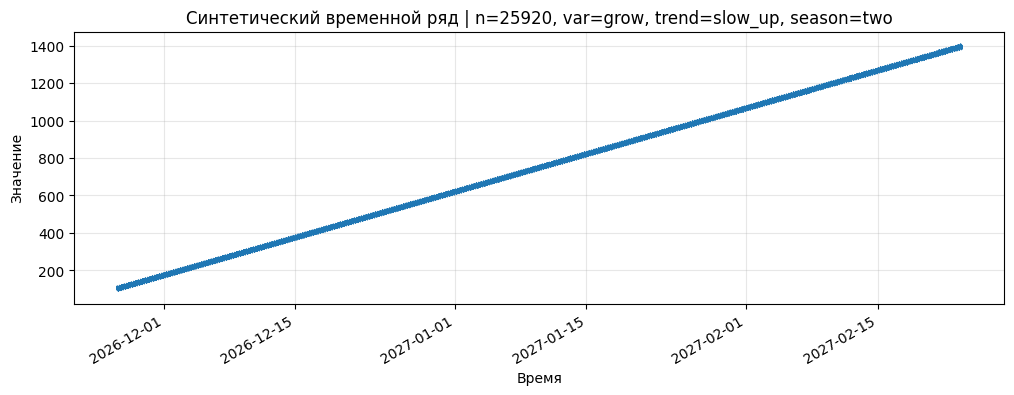

[PNG] сохранён: ./plot_20261126_195157.png

Выбранные режимы: {'variance': 'grow', 'trend': 'slow_up', 'seasonality': 'two'}


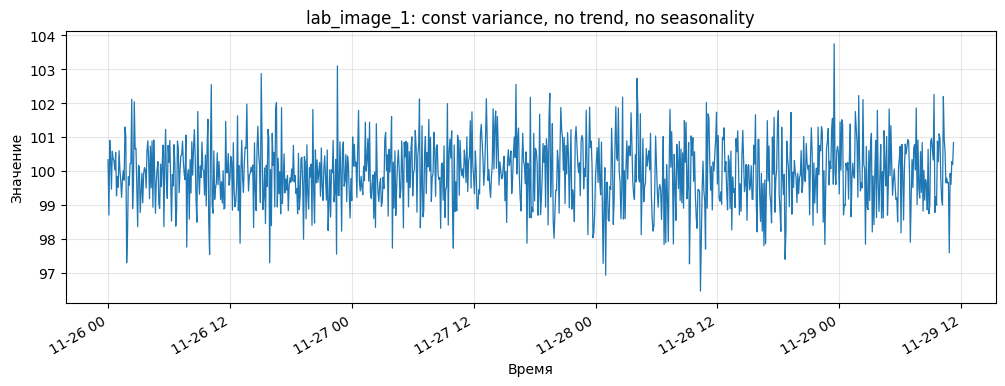

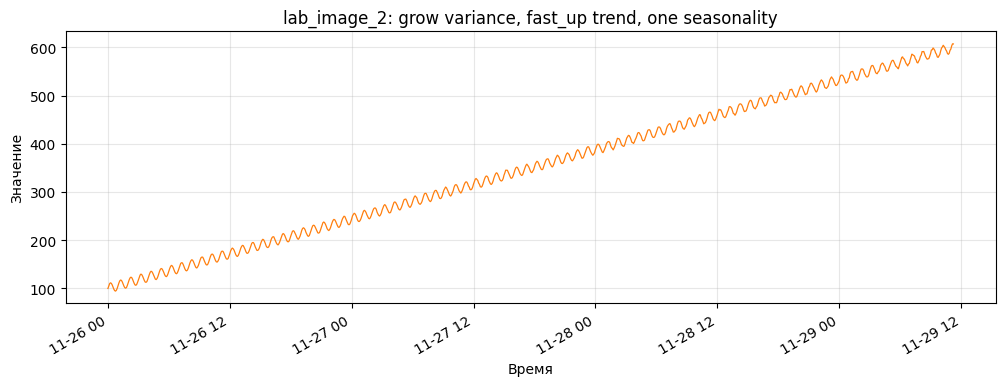

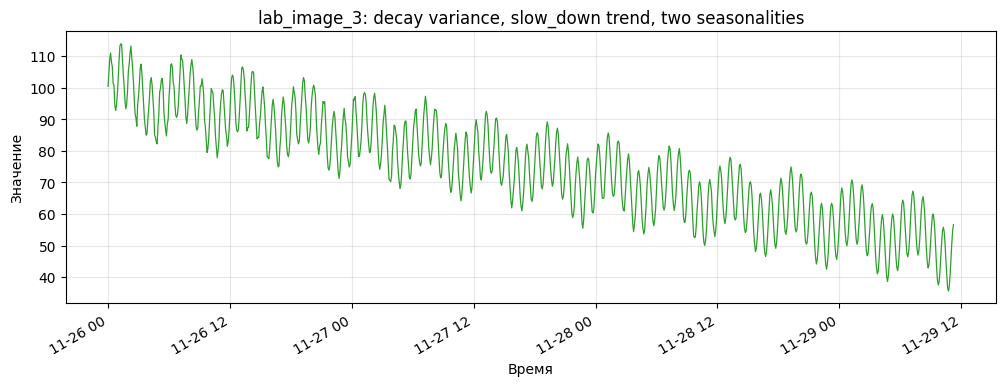

Сохранено:
 images/lab_image_1.png
 images/lab_image_2.png
 images/lab_image_3.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
from datetime import datetime, timedelta

# Настройка отображения графиков внутри ноутбука
%matplotlib inline

# np.random.seed(42)

def _apply_variance(n_points, mode='const', base_std=1.0, random_state=None):
    rng = np.random.default_rng(random_state)
    if mode == 'random':
        mode = rng.choice(['const', 'grow', 'decay'])

    t = np.linspace(0, 1, n_points)
    if mode == 'const':
        sigma = np.full(n_points, base_std)
    elif mode == 'grow':
        # Дисперсия растёт линейно от 0.1*base до base
        sigma = base_std * (0.1 + 0.9 * t)
    elif mode == 'decay':
        # Дисперсия убывает линейно от base до 0.1*base
        sigma = base_std * (1.0 - 0.9 * t)
    else:
        raise ValueError(f"Неизвестный режим дисперсии: {mode}")
    return sigma


def _apply_trend(n_points, mode='none', random_state=None):
    rng = np.random.default_rng(random_state)
    if mode == 'random':
        mode = rng.choice(['none', 'fast_up', 'slow_up', 'fast_down', 'slow_down'])

    t = np.arange(n_points, dtype=float)
    if mode == 'none':
        trend = np.zeros(n_points)
    elif mode == 'fast_up':
        trend = 0.5 * t                     # быстрый рост
    elif mode == 'slow_up':
        trend = 0.05 * t                    # медленный рост
    elif mode == 'fast_down':
        trend = -0.5 * t                    # быстрое убывание
    elif mode == 'slow_down':
        trend = -0.05 * t                   # медленное убывание
    else:
        raise ValueError(f"Неизвестный режим тренда: {mode}")
    return trend


def get_seasonality_param(season_type, season_size=0, random_state=None):
    res = 1
    rng = np.random.default_rng(random_state)

    match season_type:
        case 'minute':
            if season_size == 0:
                season_size = rng.randint(1, 60)
            res = res * season_size
        case 'hour':
            if season_size == 0:
                season_size = rng.randint(1, 24)
            res = res * 12 * season_size
        case 'day':
            if season_size == 0:
                season_size = rng.randint(1, 30)
            res = res * 12 * 24 * season_size
        case 'week':
            if season_size == 0:
                season_size = rng.randint(1, 54)
            res = res * 12 * 24 * 7 * season_size
    return res

def _apply_seasonality(n_points, mode='none', random_state=None, season_1_type = 'random', season_1_size = 0, season_2_type = 'random', season_2_size = 0):
    """
    Возвращает массив сезонной составляющей.
    Периоды: 1 час = 12 точек, 6 часов = 72 точки.
    """

    rng = np.random.default_rng(random_state)
    if mode == 'random':
        mode = rng.choice(['none', 'one', 'two'])

    if season_1_type == 'random':
        season_1_type = rng.choice(['minute','hour', 'day', 'week'])
    if season_2_type == 'random':
        season_2_type = rng.choice(['minute','hour', 'day', 'week'])

    season_1_param = get_seasonality_param(season_1_type, season_1_size, random_state)
    season_2_param = get_seasonality_param(season_2_type, season_2_size, random_state)

    t = np.arange(n_points)
    if mode == 'none':
        season = np.zeros(n_points)
    elif mode == 'one':
        # Одна сезонность: период 1 час = 12 точек
        season = 10.0 * np.sin(2 * np.pi * t / season_1_param)
    elif mode == 'two':
        # Две накладывающиеся сезонности: 1 час (12 точек) и 6 часов (72 точки)
        season = (10.0 * np.sin(2 * np.pi * t / season_1_param) +
                  5.0 * np.sin(2 * np.pi * t / season_2_param))
    else:
        raise ValueError(f"Неизвестный режим сезонности: {mode}")
    return season


def generate_time_series(
    n_points=1000,
    variance='const',
    trend='none',
    seasonality='none',
    base_value=100.0,
    base_std=1.0,
    start_time=None,
    random_state=None,
    save_csv=True,
    save_plot=True,
    output_dir='.',
    verbose=True,
    season_1_type = 'hour',
    season_1_size = 1,
    season_2_type = 'hour',
    season_2_size = 6
):
    """
    Генерирует синтетический временной ряд с шагом 5 минут, начиная с 00:00 текущего дня.

    Параметры:
        n_points     : int - количество точек (по умолчанию 1000)
        variance     : str - режим дисперсии: 'const', 'grow', 'decay', 'random'
        trend        : str - режим тренда: 'none', 'fast_up', 'slow_up', 'fast_down', 'slow_down', 'random'
        seasonality  : str - режим сезонности: 'none', 'one', 'two', 'random'
        base_value   : float - базовое значение ряда
        base_std     : float - базовое стандартное отклонение шума
        start_time   : datetime - начало ряда (по умолчанию 00:00 текущего дня)
        random_state : int - seed для воспроизводимости
        save_csv     : bool - сохранять ли CSV
        save_plot    : bool - сохранять ли PNG с графиком
        output_dir   : str - каталог для сохранения файлов
        verbose      : bool - выводить ли информацию о сохранении

    Возвращает:
        timestamps : list[datetime]
        values     : np.ndarray
        info       : dict с данными (какие режимы были выбраны)
    """
    rng = np.random.default_rng(random_state)

    # --- 1. Временные метки ---
    if start_time is None:
        now = datetime.now()
        start_time = datetime(now.year, now.month, now.day, 0, 0, 0)
    timestamps = [start_time + timedelta(minutes=5 * i) for i in range(n_points)]

    # --- 2. Разрешаем 'random' и запоминаем фактический выбор ---
    var_mode = variance
    if var_mode == 'random':
        var_mode = rng.choice(['const', 'grow', 'decay'])
    trend_mode = trend
    if trend_mode == 'random':
        trend_mode = rng.choice(['none', 'fast_up', 'slow_up', 'fast_down', 'slow_down'])
    season_mode = seasonality
    if season_mode == 'random':
        season_mode = rng.choice(['none', 'one', 'two'])

    # --- 3. Составляющие ряда ---
    sigma        = _apply_variance(n_points, var_mode, base_std, random_state=rng.integers(0, 2**31))
    trend_values = _apply_trend(n_points, trend_mode, random_state=rng.integers(0, 2**31))
    season_values = _apply_seasonality(n_points, season_mode, random_state=rng.integers(0, 2**31), season_1_type=season_1_type, season_1_size=season_1_size, season_2_type=season_2_type, season_2_size=season_2_size)
    noise        = rng.normal(0.0, 1.0, n_points) * sigma

    values = base_value + trend_values + season_values + noise

    info = {
        'n_points': n_points,
        'variance': var_mode,
        'trend': trend_mode,
        'seasonality': season_mode,
        'start_time': start_time.isoformat(),
        'base_value': base_value,
        'base_std': base_std,
    }

    # --- 4. Сохранение CSV ---
    os.makedirs(output_dir, exist_ok=True)
    csv_name = None
    if save_csv:
        now_str = datetime.now().strftime('%Y%m%d_%H%M%S')
        csv_name = os.path.join(output_dir, f'ts_{now_str}.csv')
        # суффикс при совпадении имени
        counter = 1
        while os.path.exists(csv_name):
            csv_name = os.path.join(output_dir, f'ts_{now_str}_{counter}.csv')
            counter += 1
        with open(csv_name, 'w', encoding='utf-8') as f:
            f.write('timestamp,value\n')
            for ts, v in zip(timestamps, values):
                f.write(f"{ts.strftime('%Y-%m-%d %H:%M:%S')},{v:.6f}\n")
        if verbose:
            print(f"[CSV] сохранён: {csv_name}")

    # --- 5. Визуализация и сохранение PNG ---
    plot_name = None
    if save_plot:
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.plot(timestamps, values, linewidth=0.9)
        ax.set_title(
            f"Синтетический временной ряд | n={n_points}, "
            f"var={var_mode}, trend={trend_mode}, season={season_mode}"
        )
        ax.set_xlabel('Время')
        ax.set_ylabel('Значение')
        ax.grid(True, alpha=0.3)
        fig.autofmt_xdate()
        plot_name = os.path.join(output_dir, f'plot_{datetime.now().strftime("%Y%m%d_%H%M%S")}.png')
        fig.savefig(plot_name, dpi=120, bbox_inches='tight')
        plt.show()
        if verbose:
            print(f"[PNG] сохранён: {plot_name}")

    info['csv_path'] = csv_name
    info['plot_path'] = plot_name
    return timestamps, values, info

# Генерация со случайными режимами
ts, vals, info = generate_time_series(
    n_points=90 * 24 * 12,
    variance='grow',
    trend='slow_up',
    seasonality='two',
    random_state=42,
    output_dir='.',
)
print("\nВыбранные режимы:", {k: info[k] for k in ('variance', 'trend', 'seasonality')})

# Создаём каталог images
os.makedirs('images', exist_ok=True)

# --- Изображение 1: постоянная дисперсия, без тренда, без сезонности ---
timestamps1, values1, _ = generate_time_series(
    n_points=1000,
    variance='const',
    trend='none',
    seasonality='none',
    random_state=1,
    save_csv=False,
    save_plot=False,
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(timestamps1, values1, linewidth=0.9, color='tab:blue')
ax.set_title('lab_image_1: const variance, no trend, no seasonality')
ax.set_xlabel('Время'); ax.set_ylabel('Значение'); ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.savefig('images/lab_image_1.png', dpi=120, bbox_inches='tight')
plt.show()

# --- Изображение 2: растущая дисперсия, быстрый рост, одна сезонность ---
timestamps2, values2, _ = generate_time_series(
    n_points=1000,
    variance='grow',
    trend='fast_up',
    seasonality='one',
    random_state=2,
    save_csv=False,
    save_plot=False,
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(timestamps2, values2, linewidth=0.9, color='tab:orange')
ax.set_title('lab_image_2: grow variance, fast_up trend, one seasonality')
ax.set_xlabel('Время'); ax.set_ylabel('Значение'); ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.savefig('images/lab_image_2.png', dpi=120, bbox_inches='tight')
plt.show()

# --- Изображение 3: убывающая дисперсия, медленное убывание, две сезонности ---
timestamps3, values3, _ = generate_time_series(
    n_points=1000,
    variance='decay',
    trend='slow_down',
    seasonality='two',
    random_state=3,
    save_csv=False,
    save_plot=False,
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(timestamps3, values3, linewidth=0.9, color='tab:green')
ax.set_title('lab_image_3: decay variance, slow_down trend, two seasonalities')
ax.set_xlabel('Время'); ax.set_ylabel('Значение'); ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.savefig('images/lab_image_3.png', dpi=120, bbox_inches='tight')
plt.show()

print("Сохранено:")
print(" images/lab_image_1.png")
print(" images/lab_image_2.png")
print(" images/lab_image_3.png")